In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [34]:
df = pd.read_csv('Datasets/ushape.csv')

In [35]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


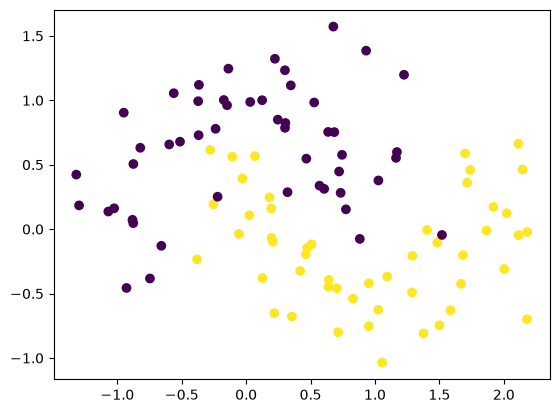

In [36]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [37]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [38]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [39]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

C:\Users\Rihan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                     │ (None, 10)                  │              30 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 10)                  │             110 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 10)                  │             110 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 10)                  │             110 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 1)                   │              11 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# Set parameters to 0
model.get_weights()

[array([[ 0.33026356,  0.5078663 , -0.24870753, -0.12516266,  0.55439276,
         -0.70058835, -0.02421826,  0.01438975,  0.05435562,  0.08795118],
        [ 0.6901447 , -0.10849172,  0.12678325, -0.6742705 , -0.23360935,
         -0.6856004 ,  0.28844512, -0.00586164,  0.31401664,  0.51259786]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.15636241, -0.502435  , -0.13684264,  0.49322355,  0.43923646,
          0.03638655, -0.09281424, -0.00935918,  0.09595931,  0.3671412 ],
        [ 0.22468895,  0.2865981 ,  0.17904514,  0.24426174, -0.24626574,
          0.47766125, -0.3273468 , -0.35522956,  0.11837524,  0.08327001],
        [ 0.2504773 ,  0.45804965,  0.1921441 ,  0.32328123,  0.1795106 ,
         -0.24162412, -0.37691486, -0.47550875,  0.38318974,  0.32335532],
        [ 0.01606458,  0.5329217 ,  0.00179756,  0.41441405, -0.38277313,
          0.3283531 ,  0.53806984,  0.14367926, -0.34165472,  0.32548296],
        [-0.29339

In [41]:
initial_weights = model.get_weights()

In [42]:
initial_weights[0] = np.random.randn(2,10)*np.sqrt(2/2)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(10,10)*np.sqrt(2/10)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(10,10)*np.sqrt(2/10)
initial_weights[5] = np.zeros(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(10,10)*np.sqrt(2/10)
initial_weights[7] = np.zeros(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(10,1)*np.sqrt(2/10)
initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [43]:
model.set_weights(initial_weights)

In [44]:
model.get_weights()

[array([[ 0.5990823 ,  1.2624536 ,  1.8669289 ,  2.5384784 , -1.1027291 ,
         -0.707386  ,  0.05475054,  0.25388846, -2.03444   , -1.0805776 ],
        [ 0.66981333, -1.2199461 ,  0.17345181, -1.2529736 ,  0.4944369 ,
         -1.7409395 , -0.494659  , -1.7773788 ,  0.9221434 , -1.9727012 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.28266573, -0.36688417, -0.16515312, -0.53988844,  0.26900572,
         -0.26129895,  0.21662924, -0.69668674,  0.78031224, -0.05768029],
        [ 0.35680324,  0.9032349 , -0.1636795 , -0.04763057, -0.43087816,
          0.07693427,  0.20806554,  0.2848982 , -0.47793704, -0.53629786],
        [ 0.15474676,  0.77861834,  0.368135  ,  0.21877001,  0.49176607,
         -0.05400062, -0.19069992,  0.00317433,  0.00186165,  0.23645568],
        [-0.00824031, -0.6186832 ,  0.5905882 ,  0.08404361, -0.41167957,
          0.6969455 , -1.068375  ,  0.25560832,  0.19051109, -0.8473407 ],
        [ 0.00556

In [45]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [46]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 381ms/step - accuracy: 0.5375 - loss: 0.6756 - val_accuracy: 0.5000 - val_loss: 0.8601
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5750 - loss: 0.6529 - val_accuracy: 0.5000 - val_loss: 0.8183
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.6250 - loss: 0.6337 - val_accuracy: 0.6000 - val_loss: 0.7780
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6375 - loss: 0.6159 - val_accuracy: 0.6000 - val_loss: 0.7418
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.6375 - loss: 0.5994 - val_accuracy: 0.6000 - val_loss: 0.7074
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.6750 - loss: 0.5840 - val_accuracy: 0.6500 - val_loss: 0.6723
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6750 - loss: 0.5683 - val_accuracy: 0.6500 - val_loss: 0.6382
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6750 - loss: 0.5531 - val_accuracy: 0.7000 - val_loss

In [47]:
model.get_weights()

[array([[ 0.55849946,  1.3244851 ,  1.8650035 ,  2.6733685 , -1.0378119 ,
         -0.6237601 ,  0.21062437,  0.3110828 , -1.9535171 , -1.1296768 ],
        [ 0.75772   , -1.2203797 ,  0.14867455, -1.1220057 ,  0.42590284,
         -1.8191999 , -0.54136115, -1.8301047 ,  1.0684457 , -1.9422703 ]],
       dtype=float32),
 array([ 0.08148763, -0.04040777, -0.07756889,  0.06992335, -0.04572569,
        -0.0265798 ,  0.0908194 ,  0.02119873,  0.03724711, -0.04841933],
       dtype=float32),
 array([[-0.17353064, -0.43063602, -0.02003595, -0.5630779 ,  0.1712241 ,
         -0.28247675,  0.21662924, -0.75411856,  0.8969989 , -0.0459817 ],
        [ 0.2712848 ,  0.97430634, -0.17609423,  0.05332429, -0.4638249 ,
          0.13644564,  0.20806554,  0.39373296, -0.5765151 , -0.5753099 ],
        [ 0.20158589,  0.7545352 ,  0.47768903,  0.25482267,  0.4069125 ,
         -0.0472954 , -0.19069992,  0.03389484,  0.06743685,  0.24591592],
        [-0.03298115, -0.59813976,  0.6144058 ,  0.15218094, 

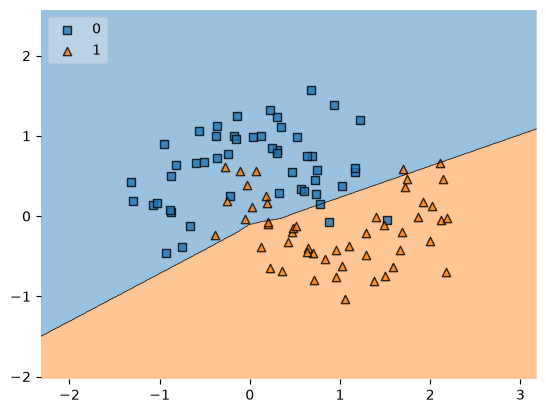

In [48]:
from mlxtend.plotting import plot_decision_regions
import numpy as np
import matplotlib.pyplot as plt

class Wrapper:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        return (self.model.predict(X, verbose=0).ravel() >= 0.5).astype(int)

plot_decision_regions(
    np.asarray(X, dtype=float),
    np.asarray(y).ravel().astype(int),
    clf=Wrapper(model),
    legend=2
)
plt.show()

In [49]:
(np.random.randn(10,10)*0.01).min()

np.float64(-0.021785807825450015)